<div dir="rtl">

# הרצאה 5: היקום החם, הסקאלה האקוסטית ו-BAO

**מה במחברת.** רקומבינציה ממשוואת Saha, אופק הקול $r_s$ והזווית $\theta_\star$, ואז נתוני BAO של DESI DR2 מול $\Lambda$CDM של Planck, כולל התאמה פשוטה של $\Omega_m$ ו-$H_0r_d$.

</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad, solve_ivp
from scipy.optimize import brentq, minimize_scalar

plt.rcParams.update({"font.size": 12, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
c = 299792.458            # km/s

# Planck 2018 (TT,TE,EE+lowE+lensing)
h = 0.6736; H0 = 100*h
ombh2, omch2 = 0.02237, 0.1200
omh2 = ombh2 + omch2 + 0.00064           # incl. one massive neutrino (0.06 eV)
Om0 = omh2/h**2
T0 = 2.7255
ogh2 = 2.4728e-5*(T0/2.7255)**4           # photons
orh2 = ogh2*(1 + 0.2271*3.046)            # photons + neutrinos (relativistic)
Or0 = orh2/h**2
OL0 = 1 - Om0 - Or0
E = lambda z: np.sqrt(Or0*(1+z)**4 + Om0*(1+z)**3 + OL0)
print(f"Om = {Om0:.4f},  z_eq = {omh2/orh2 - 1:.0f}")

Om = 0.3152,  z_eq = 3418


<div dir="rtl">

## 1. רקומבינציה: משוואת Saha
בשיווי משקל, שבר היינון $x_e$ של מימן מקיים
$$\frac{x_e^2}{1-x_e}=\frac{1}{n_b}\Big(\frac{m_ek_BT}{2\pi\hbar^2}\Big)^{3/2}e^{-B/k_BT},\qquad B=13.6\,\mathrm{eV},\quad n_b=\eta\,n_\gamma .$$
הנקודה: $\eta\sim6\times10^{-10}$ קטן מאוד, ולכן הרקומבינציה מתעכבת ל-$k_BT\approx0.3\,$eV, הרבה מתחת ל-$13.6\,$eV.

</div>

n_gamma = 411 cm^-3,  eta = 6.12e-10


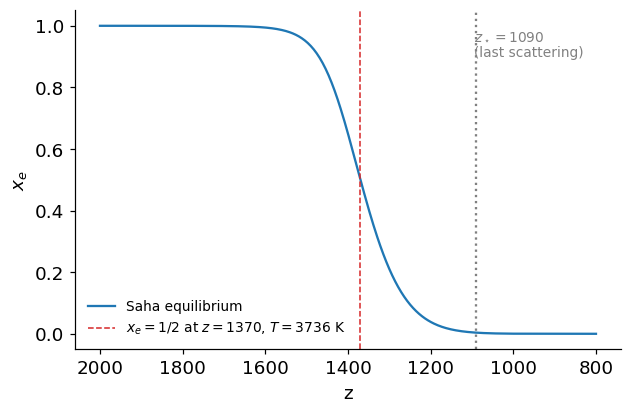

k_B T at x_e=1/2: 0.322 eV


In [2]:
kB, hbar, me, cl = 1.380649e-23, 1.054571817e-34, 9.1093837e-31, 2.99792458e8
eV = 1.602176634e-19; B = 13.6057*eV
n_gamma0 = 2*1.2020569/np.pi**2*(kB*T0/(hbar*cl))**3     # m^-3
n_b0 = ombh2*1.87834e-26/1.6735e-27*(1 - 0.245)          # hydrogen nuclei, m^-3 (Y_p=0.245)
eta = ombh2*1.87834e-26/1.6726e-27/n_gamma0
print(f"n_gamma = {n_gamma0/1e6:.0f} cm^-3,  eta = {eta:.2e}")

def x_saha(z):
    T = T0*(1+z); nb = n_b0*(1+z)**3
    S = (me*kB*T/(2*np.pi*hbar**2))**1.5*np.exp(-B/(kB*T))/nb
    return (-S + np.sqrt(S**2 + 4*S))/2                   # positive root of x^2 + S x - S = 0

zz = np.linspace(800, 2000, 500)
z_half = brentq(lambda z: x_saha(z) - 0.5, 1000, 2000)
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.plot(zz, x_saha(zz), "C0", label="Saha equilibrium")
ax.axvline(1090, color="gray", ls=":"); ax.text(1095, 0.9, r"$z_\star=1090$" "\n(last scattering)", color="gray", fontsize=9)
ax.axvline(z_half, color="C3", ls="--", lw=1, label=rf"$x_e=1/2$ at $z={z_half:.0f}$, $T={T0*(1+z_half):.0f}$ K")
ax.set_xlabel("z"); ax.set_ylabel(r"$x_e$"); ax.invert_xaxis(); ax.legend(frameon=False, fontsize=9); plt.show()
print(f"k_B T at x_e=1/2: {kB*T0*(1+z_half)/eV:.3f} eV")

<div dir="rtl">

Saha מנבא $x_e=1/2$ ב-$z\approx1370$. בפועל הרקומבינציה איטית יותר (פוטוני Ly-$\alpha$ מיננים מחדש; Peebles 1968), ופני השטח של הפיזור האחרון נמצאים ב-$z_\star\approx1090$.

## 2. אופק הקול ו-$\theta_\star$
$$r_s(z)=\int_z^\infty\frac{c_s\,dz'}{H(z')},\qquad c_s=\frac{c}{\sqrt{3(1+R)}},\qquad R=\frac{3\rho_b}{4\rho_\gamma}=\frac{3\Omega_b}{4\Omega_\gamma}\,\frac{1}{1+z}.$$

</div>

In [3]:
Rfac = 3*ombh2/(4*ogh2)
def r_s(z, with_R=True):
    integrand = lambda x: c/np.sqrt(3*(1 + (Rfac/(1+x) if with_R else 0)))/(H0*E(x))
    return quad(integrand, z, np.inf, limit=300)[0]
D_M = lambda z: c/H0*quad(lambda x: 1/E(x), 0, z, limit=300)[0]

z_star, z_drag = 1089.9, 1059.9
rs_star, rd = r_s(z_star), r_s(z_drag)
theta = rs_star/D_M(z_star)
print(f"r_s(z*)   = {rs_star:.2f} Mpc   (Planck: 144.4)")
print(f"r_d       = {rd:.2f} Mpc   (Planck: 147.1)")
print(f"r_s without baryon loading: {r_s(z_star, False):.1f} Mpc")
print(f"D_M(z*)   = {D_M(z_star):.0f} Mpc")
print(f"100 theta* = {100*theta:.4f}   (Planck: 1.0411);  acoustic scale ell_A = pi/theta = {np.pi/theta:.0f}")

r_s(z*)   = 144.28 Mpc   (Planck: 144.4)
r_d       = 146.94 Mpc   (Planck: 147.1)
r_s without baryon loading: 161.8 Mpc
D_M(z*)   = 13869 Mpc
100 theta* = 1.0403   (Planck: 1.0411);  acoustic scale ell_A = pi/theta = 302


<div dir="rtl">

**התוצאה.** חישוב פשוט, בלי שום בולצמן קוד, נותן את $100\theta_\star$ ברמת 0.1%. הסקאלה האקוסטית $\ell_A=\pi/\theta_\star\approx302$; הפסגה הראשונה יושבת ב-$\ell_1\approx0.73\,\ell_A\approx220$ בגלל הסטת פאזה. כל ההבדל מ-Planck בא מ-$z_\star$ ומ-$z_d$ שנלקחו כנתונים.

## 3. DESI DR2 מול Planck $\Lambda$CDM
DESI מודד $D_M/r_d$, $D_H/r_d=c/(H r_d)$ ו-$D_V/r_d$ (DESI Collaboration 2025, arXiv:2503.14738, טבלה IV).

</div>

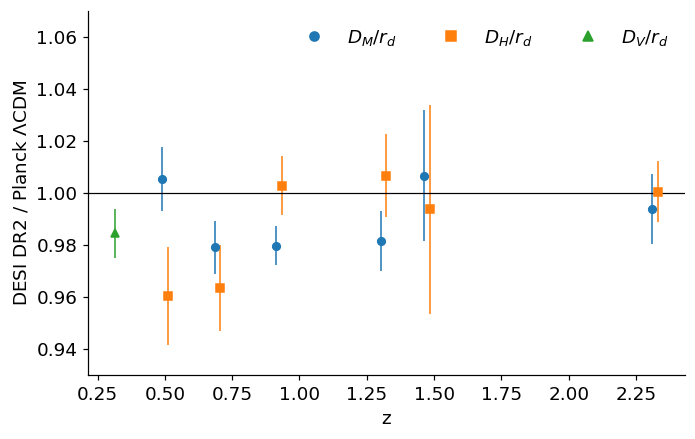

In [4]:
# DESI DR2 BAO: official means and covariance from the Cobaya likelihood files
# (github.com/CobayaSampler/bao_data, desi_bao_dr2/desi_gaussian_bao_ALL_GCcomb_*.txt)
# name, z, DV/rd, err, DM/rd, err, DH/rd, err, corr(DM,DH)
desi = [("BGS", 0.295, 7.942, 0.076, None, None, None, None, None),
        ("LRG1", 0.510, None, None, 13.588, 0.168, 21.863, 0.429, -0.452),
        ("LRG2", 0.706, None, None, 17.351, 0.180, 19.455, 0.334, -0.395),
        ("LRG3+ELG1", 0.934, None, None, 21.576, 0.162, 17.641, 0.201, -0.347),
        ("ELG2", 1.321, None, None, 27.601, 0.325, 14.176, 0.225, -0.398),
        ("QSO", 1.484, None, None, 30.512, 0.764, 12.817, 0.518, -0.494),
        ("Lya", 2.330, None, None, 38.989, 0.532, 8.632, 0.101, -0.431)]

def bao_model(z, Om, H0rd):
    # flat LCDM at low z (radiation negligible)
    Ez = lambda x: np.sqrt(Om*(1+x)**3 + 1 - Om)
    DM = c/H0rd*quad(lambda x: 1/Ez(x), 0, z)[0]
    DH = c/H0rd/Ez(z)
    return DM, DH, (z*DM**2*DH)**(1/3)

planck = dict(Om=Om0, H0rd=H0*rd)
zz = np.linspace(0.1, 2.5, 100)
fig, ax = plt.subplots(figsize=(7, 4.3))
for j, (lab, mk, col) in enumerate([(r"$D_M/r_d$", "o", "C0"), (r"$D_H/r_d$", "s", "C1"), (r"$D_V/r_d$", "^", "C2")]):
    for d in desi:
        val, err = [(d[4], d[5]), (d[6], d[7]), (d[2], d[3])][j]
        if val is None: continue
        ref = bao_model(d[1], **planck)[j]
        ax.errorbar(d[1] + 0.02*(j-1), val/ref, err/ref, fmt=mk, color=col, ms=5, lw=1)
    ax.plot([], [], mk, color=col, label=lab)
ax.axhline(1, color="k", lw=0.8)
ax.set_xlabel("z"); ax.set_ylabel(r"DESI DR2 / Planck $\Lambda$CDM"); ax.set_ylim(0.93, 1.07)
ax.legend(frameon=False, ncol=3); plt.show()

<div dir="rtl">

### התאמה: $\Omega_m$ ו-$H_0r_d$ מ-DESI בלבד
BAO לבד לא מודד את $H_0$ ואת $r_d$ בנפרד, רק את המכפלה. בונים $\chi^2$ עם מטריצת $2\times2$ לכל סל ($D_M$, $D_H$ מתואמים) ומחפשים על רשת.

</div>

best fit: Om = 0.297, H0 rd = 10150 km/s,  chi2 = 10.3 for 11 dof
Planck:   Om = 0.315, H0 rd = 9898 km/s,  chi2 = 33.4


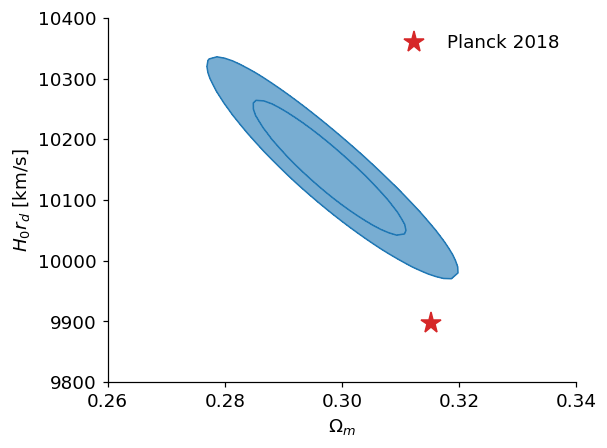

In [5]:
def chi2_desi(Om, H0rd):
    chi2 = 0.0
    for name, z, dv, sdv, dm, sdm, dh, sdh, rho in desi:
        DM, DH, DV = bao_model(z, Om, H0rd)
        if dm is None:
            chi2 += ((dv - DV)/sdv)**2; continue
        C = np.array([[sdm**2, rho*sdm*sdh], [rho*sdm*sdh, sdh**2]])
        r = np.array([dm - DM, dh - DH])
        chi2 += r @ np.linalg.solve(C, r)
    return chi2

Om_g = np.linspace(0.26, 0.34, 61); hr_g = np.linspace(9800, 10400, 61)
chi = np.array([[chi2_desi(o, hr) for hr in hr_g] for o in Om_g])
i, j = np.unravel_index(chi.argmin(), chi.shape)
print(f"best fit: Om = {Om_g[i]:.3f}, H0 rd = {hr_g[j]:.0f} km/s,  chi2 = {chi.min():.1f} for {13-2} dof")
print(f"Planck:   Om = {Om0:.3f}, H0 rd = {H0*rd:.0f} km/s,  chi2 = {chi2_desi(Om0, H0*rd):.1f}")
fig, ax = plt.subplots(figsize=(5.5, 4.3))
ax.contourf(Om_g, hr_g, (chi - chi.min()).T, levels=[0, 2.30, 6.18], colors=["C0", "C0"], alpha=0.6)
ax.contour(Om_g, hr_g, (chi - chi.min()).T, levels=[2.30, 6.18], colors="C0", linewidths=1)
ax.plot(Om0, H0*rd, "*", color="C3", ms=14, label="Planck 2018")
ax.set_xlabel(r"$\Omega_m$"); ax.set_ylabel(r"$H_0 r_d$ [km/s]"); ax.legend(frameon=False); plt.show()

<div dir="rtl">

**מה רואים.** DESI לבד מעדיף $\Omega_m\approx0.297$, נמוך מ-Planck. DESI מדווחים על מתח של $2.3\sigma$ במישור $(\Omega_m, H_0r_d)$, וזה חלק מהסיבה שצירוף DESI+CMB+סופרנובות מעדיף אנרגיה אפלה דינמית ($w_0>-1$, $w_a<0$).

---
# תרגילים פתורים נוספים

### תרגיל א: אופק הקול בנוסחה סגורה
בהזנחת $R$ ובחומר+קרינה: $r_s=\frac{2c}{\sqrt3H_0\sqrt{\Omega_m}}\big[\sqrt{a_\star+a_{\rm eq}}-\sqrt{a_{\rm eq}}\big]$. השוו לאינטגרל המלא, ואמדו את אפקט הבריונים.

</div>

In [6]:
aeq = orh2/omh2; a_star = 1/(1 + z_star)
rs_closed = 2*c/(np.sqrt(3)*H0*np.sqrt(Om0))*(np.sqrt(a_star + aeq) - np.sqrt(aeq))
print(f"closed form (R=0): {rs_closed:.1f} Mpc;  numeric (R=0): {r_s(z_star, False):.1f};  numeric with baryons: {rs_star:.1f} Mpc")
print(f"baryons reduce r_s by {100*(1 - rs_star/r_s(z_star, False)):.0f}%;  R(z*) = {Rfac/(1+z_star):.2f}")

closed form (R=0): 161.8 Mpc;  numeric (R=0): 161.8;  numeric with baryons: 144.3 Mpc
baryons reduce r_s by 11%;  R(z*) = 0.62


<div dir="rtl">

### תרגיל ב: עקמומיות מזיזה את הפסגה
עם $\Omega_mh^2$ ו-$\Omega_bh^2$ קבועים (ולכן $r_s$ קבוע), הוסיפו $\Omega_k=\pm0.05$ (על חשבון $\Omega_\Lambda$) וחשבו את $\ell_A=\pi D_M/r_s$.

</div>

In [7]:
def DM_curved(z, Ok):
    OL = 1 - Om0 - Or0 - Ok
    Ez = lambda x: np.sqrt(Or0*(1+x)**4 + Om0*(1+x)**3 + Ok*(1+x)**2 + OL)
    x = quad(lambda t: 1/Ez(t), 0, z, limit=300)[0]
    if abs(Ok) < 1e-8: return c/H0*x
    s = np.sqrt(abs(Ok))
    return c/H0*(np.sinh(s*x) if Ok > 0 else np.sin(s*x))/s
for Ok in (-0.05, 0.0, 0.05):
    print(f"Omega_k = {Ok:+.2f}:  ell_A = pi D_M/r_s = {np.pi*DM_curved(z_star, Ok)/rs_star:.0f},  first peak ~ 0.73 ell_A = {0.73*np.pi*DM_curved(z_star, Ok)/rs_star:.0f}")

Omega_k = -0.05:  ell_A = pi D_M/r_s = 281,  first peak ~ 0.73 ell_A = 205
Omega_k = +0.00:  ell_A = pi D_M/r_s = 302,  first peak ~ 0.73 ell_A = 220
Omega_k = +0.05:  ell_A = pi D_M/r_s = 323,  first peak ~ 0.73 ell_A = 235


<div dir="rtl">

**מסקנה.** יקום סגור ($\Omega_k<0$) מזיז את הפסגות לזוויות גדולות (ℓ קטן), ופתוח מזיז אותן ל-ℓ גדול. $\Omega_k=\pm0.05$ כבר מזיז את הפסגה הראשונה ב-$\pm15$, ולכן המיקום הנמדד, $\ell_1\approx220$, אומר לנו שהיקום כמעט שטוח.

### תרגיל ג: נקודת DESI אחת
LRG2 ב-$z=0.706$: $D_H/r_d=19.46\pm0.33$. עם $r_d=147.09\,$Mpc, מה $H(z)$? מה $\Lambda$CDM של Planck חוזה?

</div>

In [8]:
z_, dh, sdh = 0.706, 19.455, 0.334
Hz = c/(dh*147.09); sH = Hz*sdh/dh
print(f"H(z=0.706) = {Hz:.1f} ± {sH:.1f} km/s/Mpc;  Planck LCDM: {H0*E(z_):.1f} km/s/Mpc")

H(z=0.706) = 104.8 ± 1.8 km/s/Mpc;  Planck LCDM: 101.1 km/s/Mpc
